# Phase C — Exploratory Data Analysis

**Project:** PM Accelerator AI Engineer Intern assessment  
**Inputs:** cleaned row-level, city-day, and global core data from Phase B  
**Scope:** descriptive EDA only. No forecasting model is trained, no
train/test split is defined, and no forecast metric is calculated.

The headline global trend uses only the **183 core locations** and only
UTC dates with `coverage_ok == True` (at least 150 cities). City and
country comparisons use core city-day data and are described with
coverage caveats.

## 1. Analysis scope and data checks

Questions for this phase:

1. How complete and balanced is the cleaned panel?
2. What does the equal-weighted global core temperature series show?
3. How much do cities differ in level and seasonal amplitude?
4. Which weather relationships hold *within* cities rather than only
   across cities?
5. What do conditions and air quality look like descriptively?

These are observational questions. The data cover May 2024–October
2026, so they cannot establish a long-term climate trend.

In [1]:
import sys
from pathlib import Path

import calendar
import textwrap

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LogNorm, Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import spearmanr

from src.config import REPORT_DIR
from src.eda import (
    CORRELATION_COLUMNS,
    SHORT_LABELS,
    TIER_COLORS,
    city_temperature_summary,
    core_city_days,
    load_eda_data,
    monthly_global,
    save_figure,
    seasonal_amplitude,
    set_plot_style,
    tier_summary,
    within_city_spearman,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
set_plot_style()

city_daily, global_daily = load_eda_data()
core = core_city_days(city_daily)
tier_table = tier_summary(city_daily)
city_summary = city_temperature_summary(city_daily)
monthly = monthly_global(global_daily)
amplitude = seasonal_amplitude(city_daily)

print(f"City-day rows: {len(city_daily):,}")
print(f"Core city-days: {len(core):,}")
print(f"Core cities: {core.groupby(['country', 'city']).ngroups}")
print(
    "City-day date range:",
    city_daily["date_local"].min().date(),
    "->",
    city_daily["date_local"].max().date(),
)
print(
    "Global UTC date range:",
    global_daily["date_utc"].min().date(),
    "->",
    global_daily["date_utc"].max().date(),
)
print(
    "Global usable dates:",
    int(global_daily["coverage_ok"].sum()),
    "of",
    len(global_daily),
)
print(
    "Duplicate city-day keys:",
    int(city_daily.duplicated(["country", "city", "date_local"]).sum()),
)
print("Missing core temperatures:", int(core["temperature_celsius"].isna().sum()))
display(tier_table)

City-day rows: 170,511
Core city-days: 159,905
Core cities: 183
City-day date range: 2024-05-16 -> 2026-10-13
Global UTC date range: 2024-05-16 -> 2026-10-13
Global usable dates: 875 of 879
Duplicate city-day keys: 0
Missing core temperatures: 1


,location_tier,rows,groups
0,core,159905,183
1,partial,9983,33
2,sparse,623,53


## 2. Coverage and data completeness

The panel is intentionally unbalanced: 183 locations have almost the
full 880-day record, 33 are partial, and 53 are sparse. The EDA
therefore separates **core** city series from the long tail and never
treats the sparse groups as equivalent evidence.

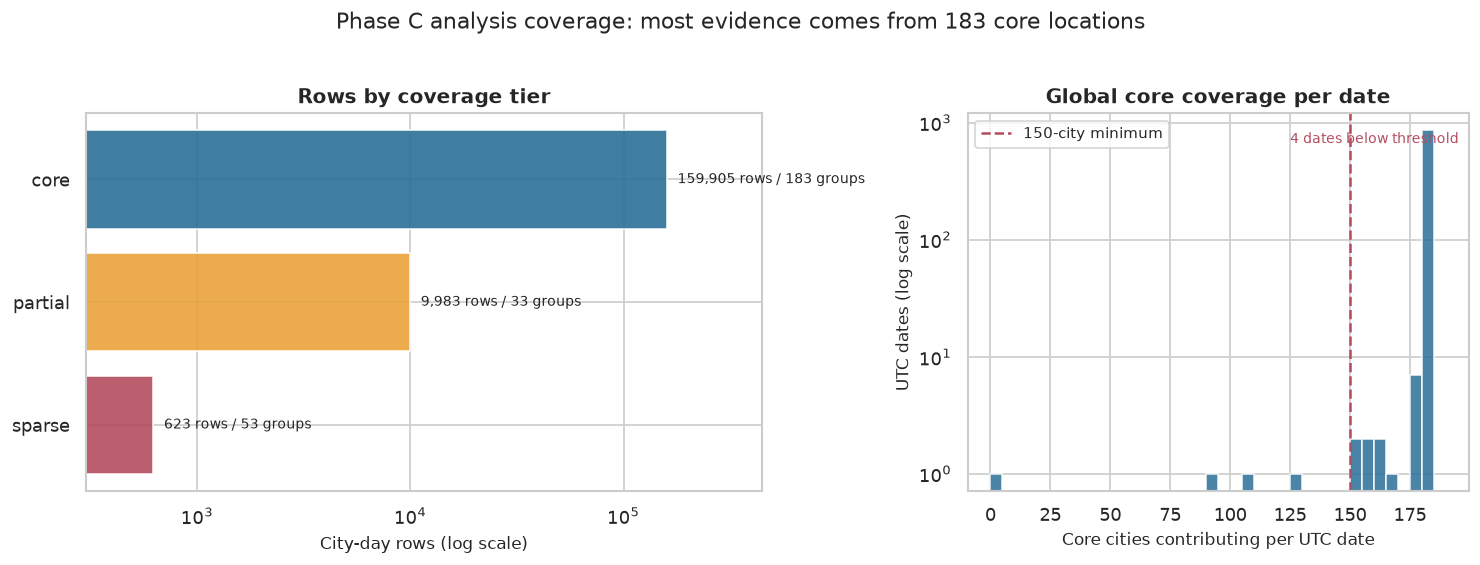

fig_01_coverage_summary.png


In [2]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.5, 4.6),
    gridspec_kw={"width_ratios": [1.35, 1.0]},
)

ax = axes[0]
y = np.arange(len(tier_table))
bars = ax.barh(
    y,
    tier_table["rows"],
    color=[TIER_COLORS[t] for t in tier_table["location_tier"]],
    alpha=0.9,
)
ax.set_yticks(y, tier_table["location_tier"])
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("City-day rows (log scale)")
ax.set_title("Rows by coverage tier")
for bar, row in zip(bars, tier_table.itertuples()):
    ax.text(
        row.rows * 1.12,
        bar.get_y() + bar.get_height() / 2,
        f"{row.rows:,} rows / {row.groups} groups",
        va="center",
        fontsize=8.5,
    )
ax.set_xlim(300, tier_table["rows"].max() * 2.8)

ax = axes[1]
counts = global_daily["n_cities"]
ax.hist(counts, bins=np.arange(0, 195, 5), color="#2A6F97", alpha=0.85)
ax.axvline(150, color="#B44C5E", linestyle="--", linewidth=1.5, label="150-city minimum")
ax.set_yscale("log")
ax.set_xlabel("Core cities contributing per UTC date")
ax.set_ylabel("UTC dates (log scale)")
ax.set_title("Global core coverage per date")
ax.legend(frameon=True, loc="upper left")
ax.text(
    0.98,
    0.95,
    f"{int((counts < 150).sum())} dates below threshold",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8.5,
    color="#B44C5E",
)

fig.suptitle(
    "Phase C analysis coverage: most evidence comes from 183 core locations",
    fontsize=13,
    y=1.02,
)
fig.tight_layout()
path = save_figure(fig, "fig_01_coverage_summary.png")
plt.show()
print(path.name)

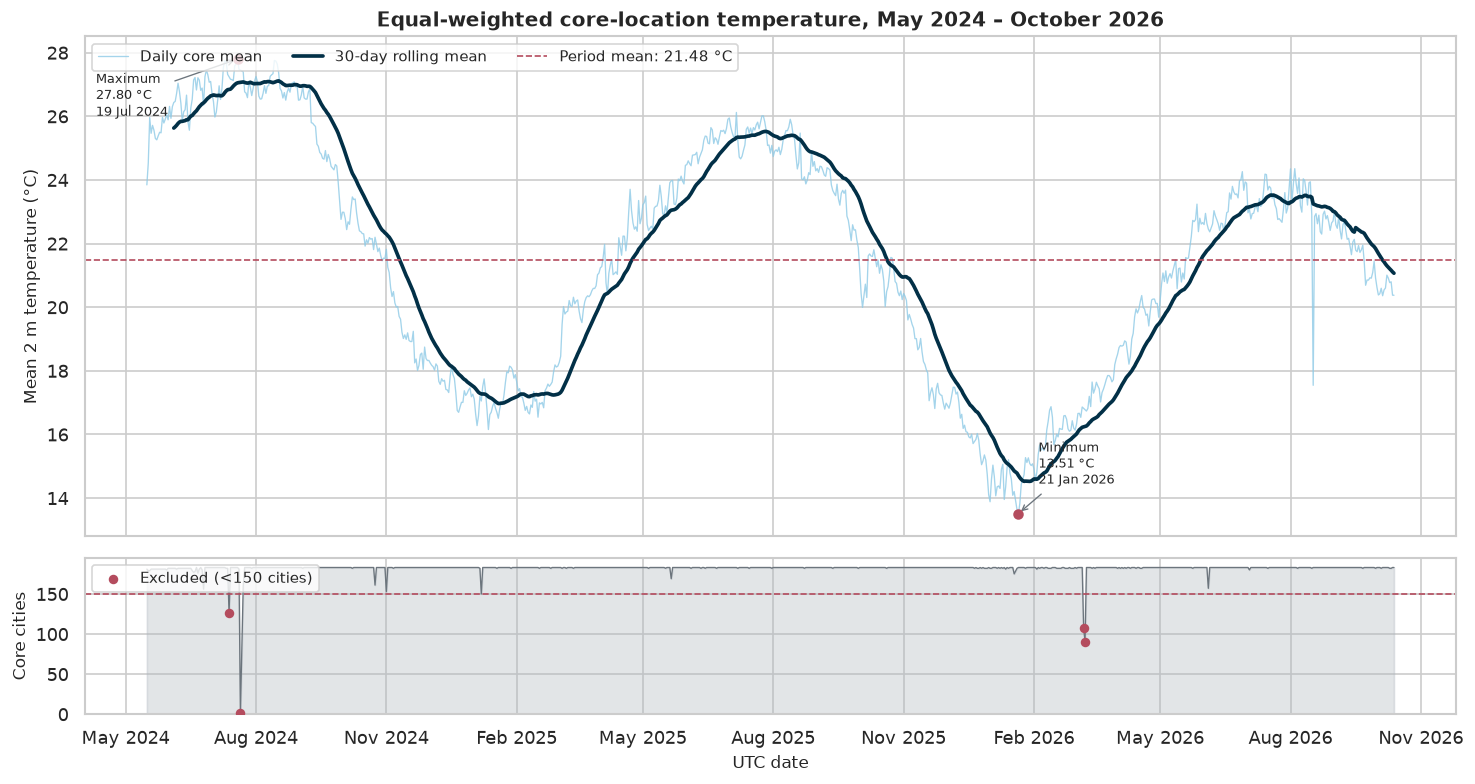

fig_02_global_temperature_and_coverage.png
Daily range: 13.51 to 27.80 °C
30-day rolling range: 14.52 to 27.11 °C


In [3]:
usable = global_daily.loc[global_daily["coverage_ok"]].sort_values("date_utc").copy()
usable["temp_30d"] = usable["temperature_celsius"].rolling(30, min_periods=20).mean()

fig, (ax, ax_cov) = plt.subplots(
    2,
    1,
    figsize=(12.5, 6.7),
    sharex=True,
    gridspec_kw={"height_ratios": [3.2, 1.0]},
)

ax.plot(
    usable["date_utc"],
    usable["temperature_celsius"],
    color="#8ECAE6",
    linewidth=0.8,
    alpha=0.8,
    label="Daily core mean",
)
ax.plot(
    usable["date_utc"],
    usable["temp_30d"],
    color="#023047",
    linewidth=2.2,
    label="30-day rolling mean",
)
overall_mean = usable["temperature_celsius"].mean()
ax.axhline(
    overall_mean,
    color="#B44C5E",
    linestyle="--",
    linewidth=1.0,
    label=f"Period mean: {overall_mean:.2f} °C",
)

min_row = usable.loc[usable["temperature_celsius"].idxmin()]
max_row = usable.loc[usable["temperature_celsius"].idxmax()]
ax.scatter(
    [min_row["date_utc"], max_row["date_utc"]],
    [min_row["temperature_celsius"], max_row["temperature_celsius"]],
    color="#B44C5E",
    s=28,
    zorder=4,
)
ax.annotate(
    f"Minimum\n{min_row['temperature_celsius']:.2f} °C\n{min_row['date_utc']:%d %b %Y}",
    xy=(min_row["date_utc"], min_row["temperature_celsius"]),
    xytext=(12, 18),
    textcoords="offset points",
    fontsize=8,
    arrowprops={"arrowstyle": "->", "color": "#6C757D", "lw": 0.8},
)
ax.annotate(
    f"Maximum\n{max_row['temperature_celsius']:.2f} °C\n{max_row['date_utc']:%d %b %Y}",
    xy=(max_row["date_utc"], max_row["temperature_celsius"]),
    xytext=(-85, -34),
    textcoords="offset points",
    fontsize=8,
    arrowprops={"arrowstyle": "->", "color": "#6C757D", "lw": 0.8},
)
ax.set_ylabel("Mean 2 m temperature (°C)")
ax.set_title("Equal-weighted core-location temperature, May 2024 – October 2026")
ax.legend(loc="upper left", ncol=3, frameon=True)

ax_cov.plot(
    global_daily["date_utc"],
    global_daily["n_cities"],
    color="#6C757D",
    linewidth=0.8,
)
ax_cov.fill_between(
    global_daily["date_utc"],
    0,
    global_daily["n_cities"],
    color="#ADB5BD",
    alpha=0.35,
)
excluded = global_daily.loc[~global_daily["coverage_ok"]]
ax_cov.scatter(
    excluded["date_utc"],
    excluded["n_cities"],
    color="#B44C5E",
    s=22,
    zorder=3,
    label="Excluded (<150 cities)",
)
ax_cov.axhline(150, color="#B44C5E", linestyle="--", linewidth=1.0)
ax_cov.set_ylim(0, 195)
ax_cov.set_ylabel("Core cities")
ax_cov.set_xlabel("UTC date")
ax_cov.legend(loc="upper left", frameon=True)

locator = mdates.MonthLocator(interval=3)
formatter = mdates.DateFormatter("%b %Y")
ax_cov.xaxis.set_major_locator(locator)
ax_cov.xaxis.set_major_formatter(formatter)
for label in ax_cov.get_xticklabels():
    label.set_rotation(0)
    label.set_ha("center")

fig.tight_layout()
path = save_figure(fig, "fig_02_global_temperature_and_coverage.png")
plt.show()
print(path.name)
print(
    f"Daily range: {usable['temperature_celsius'].min():.2f} to "
    f"{usable['temperature_celsius'].max():.2f} °C"
)
print(
    f"30-day rolling range: {usable['temp_30d'].min():.2f} to "
    f"{usable['temp_30d'].max():.2f} °C"
)

## 3. Global temperature and seasonality

The global series is a city-equal-weighted average, not a population-
weighted or area-weighted global temperature. It is useful for
describing the panel, not for estimating the Earth's absolute mean
temperature.

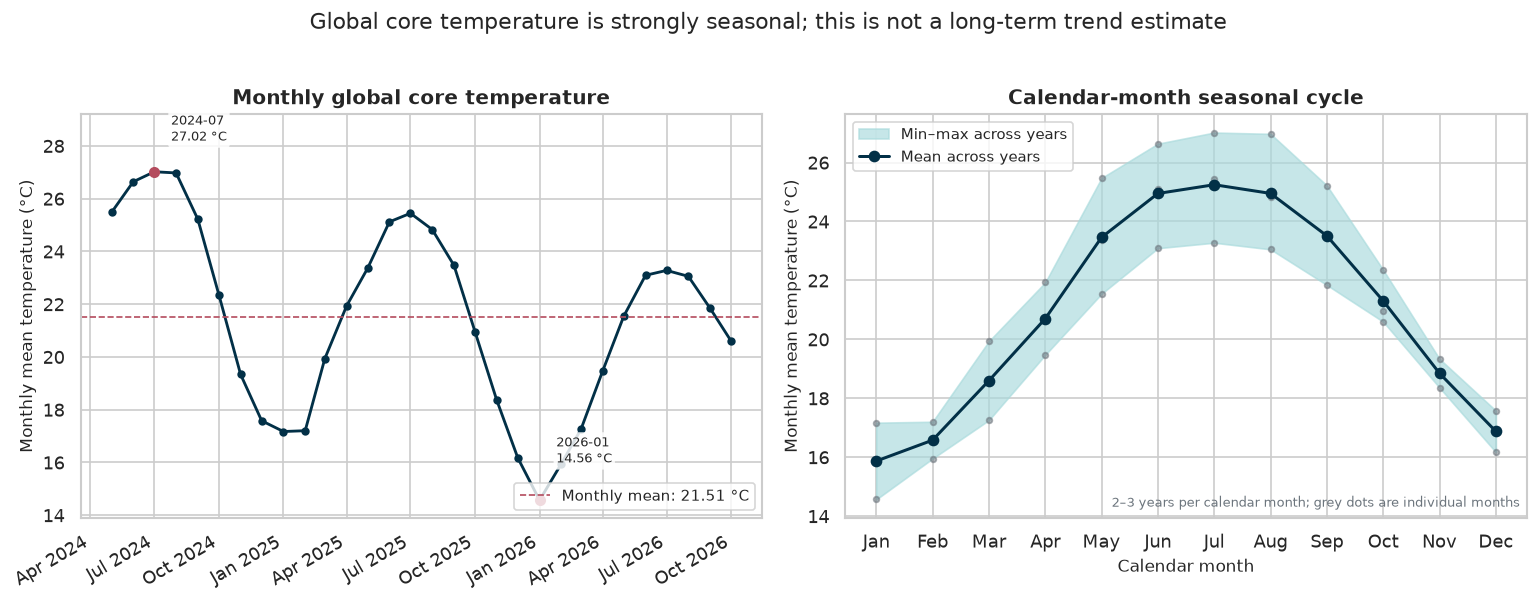

fig_03_monthly_seasonal_cycle.png


,month_label,n_days,mean_temp,mean_cities
18,2025-11,30,18.357450,183.000000
19,2025-12,31,16.169269,182.774194
20,2026-01,30,14.564706,182.400000
21,2026-02,28,15.951215,182.428571
22,2026-03,29,17.256151,182.862069
23,2026-04,30,19.471623,182.733333
24,2026-05,31,21.545324,182.967742
25,2026-06,30,23.092727,182.133333
26,2026-07,31,23.278061,182.870968
27,2026-08,31,23.053866,182.935484


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.9))

ax = axes[0]
ax.plot(
    monthly["month_start"],
    monthly["mean_temp"],
    color="#023047",
    marker="o",
    markersize=4,
    linewidth=1.7,
)
ax.axhline(
    monthly["mean_temp"].mean(),
    color="#B44C5E",
    linestyle="--",
    linewidth=1.0,
    label=f"Monthly mean: {monthly['mean_temp'].mean():.2f} °C",
)
min_month = monthly.loc[monthly["mean_temp"].idxmin()]
max_month = monthly.loc[monthly["mean_temp"].idxmax()]
ax.scatter(
    [min_month["month_start"], max_month["month_start"]],
    [min_month["mean_temp"], max_month["mean_temp"]],
    color="#B44C5E",
    s=32,
    zorder=3,
)
label_box = {"boxstyle": "round,pad=0.2", "facecolor": "white", "alpha": 0.85, "edgecolor": "none"}
ax.annotate(
    f"{min_month['month_label']}\n{min_month['mean_temp']:.2f} °C",
    xy=(min_month["month_start"], min_month["mean_temp"]),
    xytext=(10, 20),
    textcoords="offset points",
    fontsize=8,
    ha="left",
    va="bottom",
    bbox=label_box,
)
ax.annotate(
    f"{max_month['month_label']}\n{max_month['mean_temp']:.2f} °C",
    xy=(max_month["month_start"], max_month["mean_temp"]),
    xytext=(10, 16),
    textcoords="offset points",
    fontsize=8,
    ha="left",
    va="bottom",
    bbox=label_box,
)
ax.set_ylabel("Monthly mean temperature (°C)")
ax.set_ylim(13.9, 29.2)
ax.set_title("Monthly global core temperature")
ax.legend(loc="lower right", frameon=True)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for label in ax.get_xticklabels():
    label.set_rotation(30)
    label.set_ha("right")

ax = axes[1]
cal = (
    monthly.groupby(["month_num", "month_name"])
    .agg(
        mean_temp=("mean_temp", "mean"),
        min_temp=("mean_temp", "min"),
        max_temp=("mean_temp", "max"),
        n_years=("mean_temp", "size"),
    )
    .reset_index()
    .sort_values("month_num")
)
ax.fill_between(
    cal["month_num"],
    cal["min_temp"],
    cal["max_temp"],
    color="#A8DADC",
    alpha=0.65,
    label="Min–max across years",
)
for row in monthly.itertuples():
    ax.scatter(
        row.month_num,
        row.mean_temp,
        color="#6C757D",
        s=12,
        alpha=0.55,
        zorder=2,
    )
ax.plot(
    cal["month_num"],
    cal["mean_temp"],
    color="#023047",
    marker="o",
    linewidth=1.8,
    label="Mean across years",
)
ax.set_xticks(range(1, 13), [calendar.month_abbr[m] for m in range(1, 13)])
ax.set_xlabel("Calendar month")
ax.set_ylabel("Monthly mean temperature (°C)")
ax.set_title("Calendar-month seasonal cycle")
ax.legend(loc="upper left", frameon=True)
ax.text(
    0.99,
    0.02,
    "2–3 years per calendar month; grey dots are individual months",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=7.5,
    color="#6C757D",
)

fig.suptitle(
    "Global core temperature is strongly seasonal; this is not a long-term trend estimate",
    fontsize=13,
    y=1.02,
)
fig.tight_layout()
path = save_figure(fig, "fig_03_monthly_seasonal_cycle.png")
plt.show()
print(path.name)
display(monthly[["month_label", "n_days", "mean_temp", "mean_cities"]].tail(12))

## 4. Temperature distributions

City-day values pool very different climates. The per-city means in the
right panel are the more appropriate unit for comparing locations.

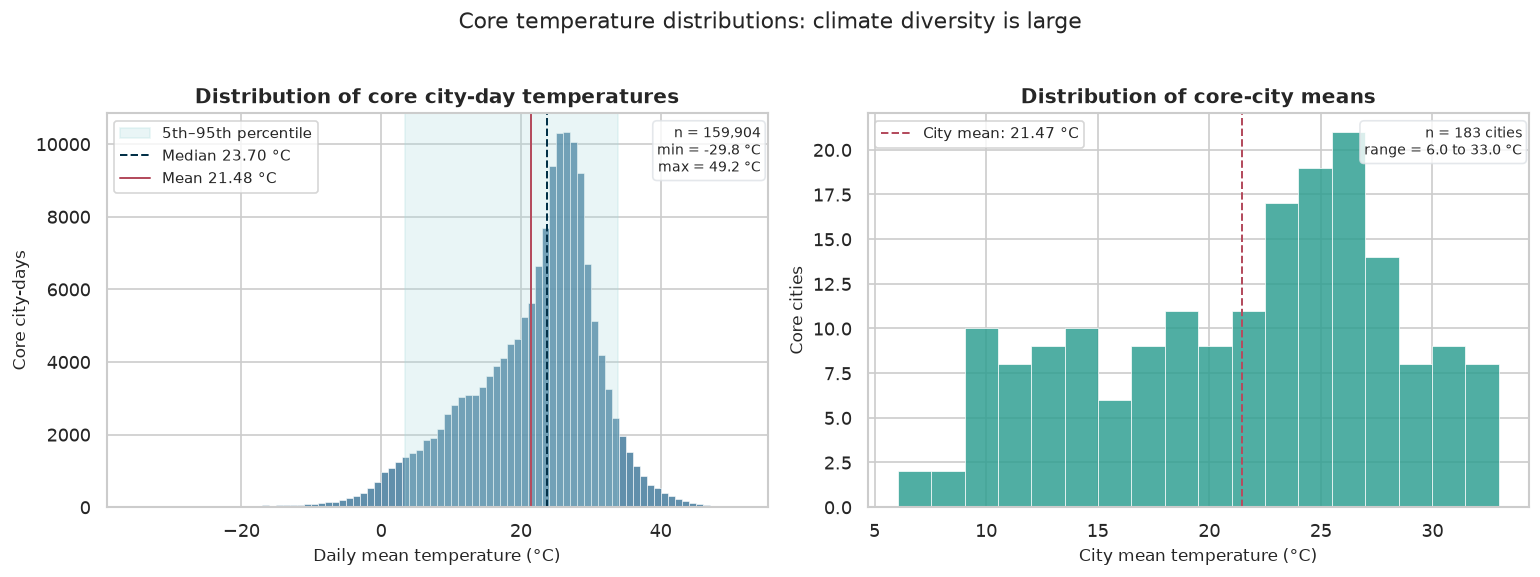

fig_04_temperature_distributions.png
count    159904.00
mean         21.48
std           9.28
min         -29.80
25%          16.20
50%          23.70
75%          27.70
max          49.20


In [5]:
temps = core["temperature_celsius"].dropna()
p05, p50, mean_temp, p95 = (
    temps.quantile(0.05),
    temps.median(),
    temps.mean(),
    temps.quantile(0.95),
)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.7))

ax = axes[0]
ax.hist(
    temps,
    bins=np.arange(-35, 52, 1),
    color="#457B9D",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.4,
)
ax.axvspan(p05, p95, color="#A8DADC", alpha=0.25, label="5th–95th percentile")
ax.axvline(p50, color="#023047", linestyle="--", linewidth=1.2, label=f"Median {p50:.2f} °C")
ax.axvline(mean_temp, color="#B44C5E", linestyle="-", linewidth=1.2, label=f"Mean {mean_temp:.2f} °C")
ax.set_xlabel("Daily mean temperature (°C)")
ax.set_ylabel("Core city-days")
ax.set_title("Distribution of core city-day temperatures")
ax.legend(loc="upper left", frameon=True)
ax.text(
    0.99,
    0.97,
    f"n = {len(temps):,}\nmin = {temps.min():.1f} °C\nmax = {temps.max():.1f} °C",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8.5,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "alpha": 0.8, "edgecolor": "#DEE2E6"},
)

ax = axes[1]
ax.hist(
    city_summary["mean_temp"],
    bins=18,
    color="#2A9D8F",
    alpha=0.82,
    edgecolor="white",
    linewidth=0.5,
)
ax.axvline(
    city_summary["mean_temp"].mean(),
    color="#B44C5E",
    linestyle="--",
    linewidth=1.2,
    label=f"City mean: {city_summary['mean_temp'].mean():.2f} °C",
)
ax.set_xlabel("City mean temperature (°C)")
ax.set_ylabel("Core cities")
ax.set_title("Distribution of core-city means")
ax.legend(loc="upper left", frameon=True)
ax.text(
    0.99,
    0.97,
    f"n = {len(city_summary)} cities\nrange = {city_summary['mean_temp'].min():.1f} to "
    f"{city_summary['mean_temp'].max():.1f} °C",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8.5,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "alpha": 0.8, "edgecolor": "#DEE2E6"},
)

fig.suptitle("Core temperature distributions: climate diversity is large", fontsize=13, y=1.02)
fig.tight_layout()
path = save_figure(fig, "fig_04_temperature_distributions.png")
plt.show()
print(path.name)
print(temps.describe().round(2).to_string())

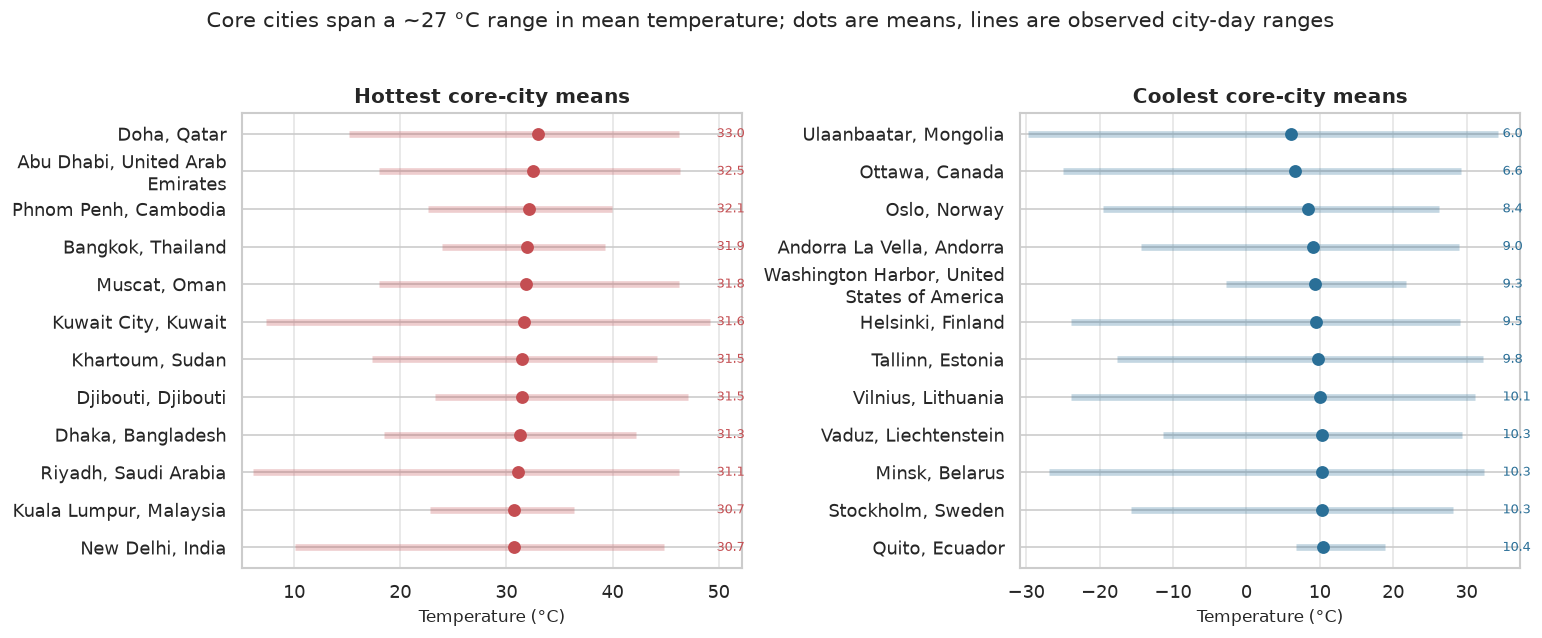

fig_05_city_temperature_extremes.png


In [6]:
hot = city_summary.nlargest(12, "mean_temp").sort_values("mean_temp", ascending=False)
cold = city_summary.nsmallest(12, "mean_temp").sort_values("mean_temp", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.2))

for ax, data, color, title in [
    (axes[0], hot, "#C44E52", "Hottest core-city means"),
    (axes[1], cold, "#2A6F97", "Coolest core-city means"),
]:
    y = np.arange(len(data))
    ax.hlines(
        y,
        data["min_temp"],
        data["max_temp"],
        color=color,
        alpha=0.28,
        linewidth=4,
        zorder=1,
    )
    ax.scatter(data["mean_temp"], y, color=color, s=45, zorder=3)
    labels = [
        textwrap.fill(f"{row.city}, {row.country}", 30) for row in data.itertuples()
    ]
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlabel("Temperature (°C)")
    ax.set_title(title)
    x_right = data["max_temp"].max()
    for ypos, row in enumerate(data.itertuples()):
        ax.text(
            x_right + 0.6,
            ypos,
            f"{row.mean_temp:.1f}",
            va="center",
            fontsize=8,
            color=color,
        )
    ax.set_xlim(
        min(data["min_temp"].min() - 1, data["mean_temp"].min() - 2),
        data["max_temp"].max() + 3.0,
    )
    ax.grid(axis="x", alpha=0.5)

fig.suptitle(
    "Core cities span a ~27 °C range in mean temperature; dots are means, lines are observed city-day ranges",
    fontsize=12.5,
    y=1.02,
)
fig.tight_layout()
path = save_figure(fig, "fig_05_city_temperature_extremes.png")
plt.show()
print(path.name)

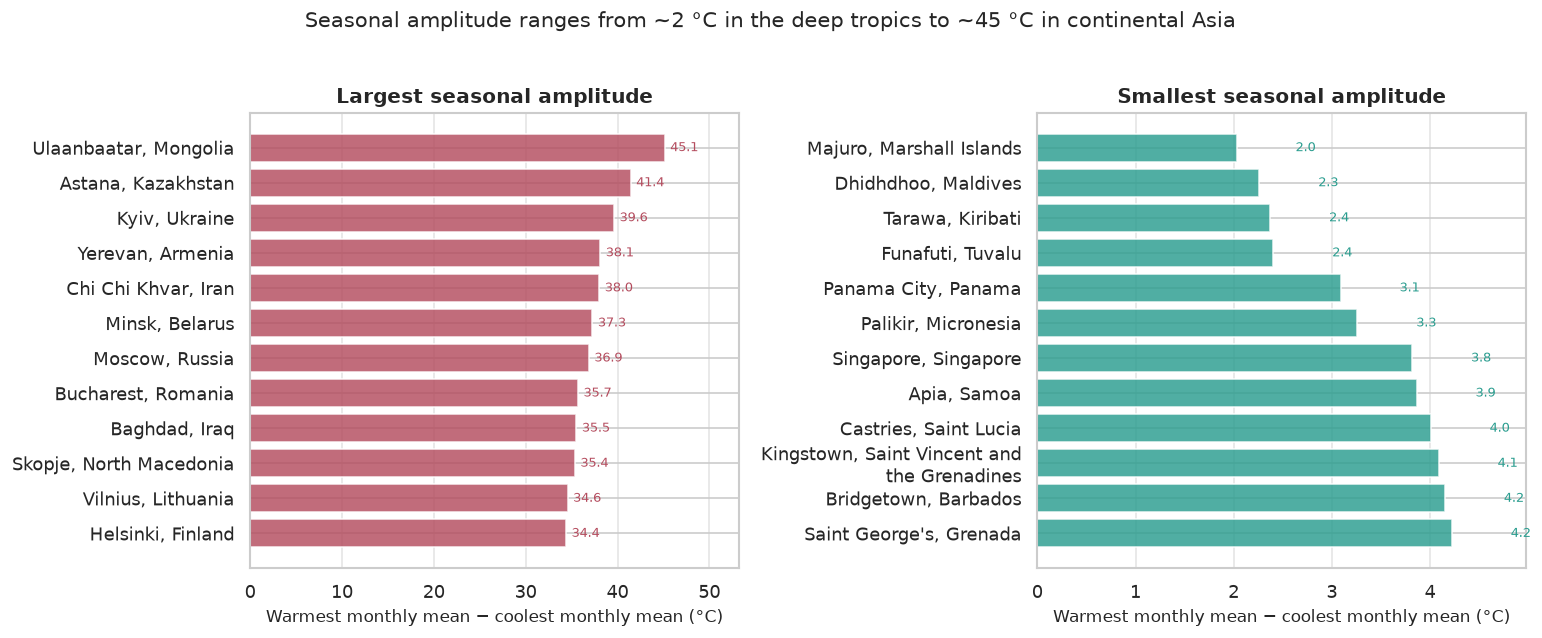

fig_06_seasonal_amplitude.png
Amplitude cities: 183; months required: >=12


In [7]:
amp_top = amplitude.nlargest(12, "amplitude").sort_values("amplitude", ascending=False)
amp_bottom = amplitude.nsmallest(12, "amplitude").sort_values("amplitude", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.2))

for ax, data, color, title in [
    (axes[0], amp_top, "#B44C5E", "Largest seasonal amplitude"),
    (axes[1], amp_bottom, "#2A9D8F", "Smallest seasonal amplitude"),
]:
    y = np.arange(len(data))
    ax.barh(y, data["amplitude"], color=color, alpha=0.82)
    labels = [textwrap.fill(f"{row.city}, {row.country}", 30) for row in data.itertuples()]
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlabel("Warmest monthly mean − coolest monthly mean (°C)")
    ax.set_title(title)
    for ypos, value in enumerate(data["amplitude"]):
        ax.text(value + 0.6, ypos, f"{value:.1f}", va="center", fontsize=8, color=color)
    ax.set_xlim(0, data["amplitude"].max() * 1.18)
    ax.grid(axis="x", alpha=0.5)

fig.suptitle(
    "Seasonal amplitude ranges from ~2 °C in the deep tropics to ~45 °C in continental Asia",
    fontsize=12.5,
    y=1.02,
)
fig.tight_layout()
path = save_figure(fig, "fig_06_seasonal_amplitude.png")
plt.show()
print(path.name)
print(f"Amplitude cities: {len(amplitude)}; months required: >=12")

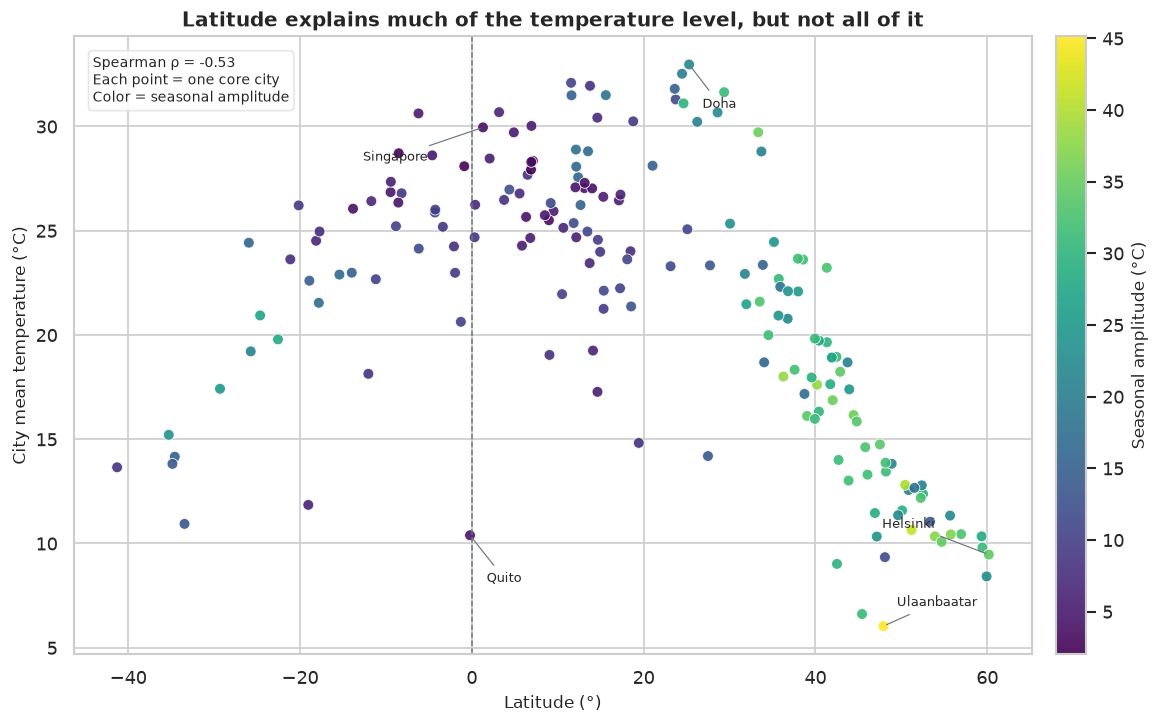

fig_07_latitude_and_temperature.png


In [8]:
fig, ax = plt.subplots(figsize=(10.5, 6.2))
scatter = ax.scatter(
    amplitude["lat"],
    amplitude["mean_temp"],
    c=amplitude["amplitude"],
    cmap="viridis",
    s=42,
    edgecolor="white",
    linewidth=0.5,
    alpha=0.9,
)
ax.axvline(0, color="#6C757D", linestyle="--", linewidth=0.9)
ax.set_xlabel("Latitude (°)")
ax.set_ylabel("City mean temperature (°C)")
ax.set_title("Latitude explains much of the temperature level, but not all of it")

rho = spearmanr(amplitude["lat"], amplitude["mean_temp"]).statistic
ax.text(
    0.02,
    0.97,
    f"Spearman ρ = {rho:.2f}\nEach point = one core city\nColor = seasonal amplitude",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=8.5,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "alpha": 0.85, "edgecolor": "#DEE2E6"},
)

annotate = {
    "Doha": (8, -26),
    "Ulaanbaatar": (8, 12),
    "Quito": (10, -28),
    "Singapore": (-72, -20),
    "Helsinki": (-64, 16),
}
for city, offset in annotate.items():
    row = amplitude.loc[amplitude["city"].eq(city)]
    if row.empty:
        continue
    row = row.iloc[0]
    ax.annotate(
        city,
        xy=(row["lat"], row["mean_temp"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=8,
        arrowprops={"arrowstyle": "-", "color": "#6C757D", "lw": 0.7},
    )

cbar = fig.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label("Seasonal amplitude (°C)")
fig.tight_layout()
path = save_figure(fig, "fig_07_latitude_and_temperature.png")
plt.show()
print(path.name)

## 5. Relationships and air quality

Pooled correlations across cities can be confounded by latitude,
altitude, and local climate. The heatmap below therefore shows the
**median within-city Spearman correlation** across the 183 core cities.
It is descriptive, not causal.

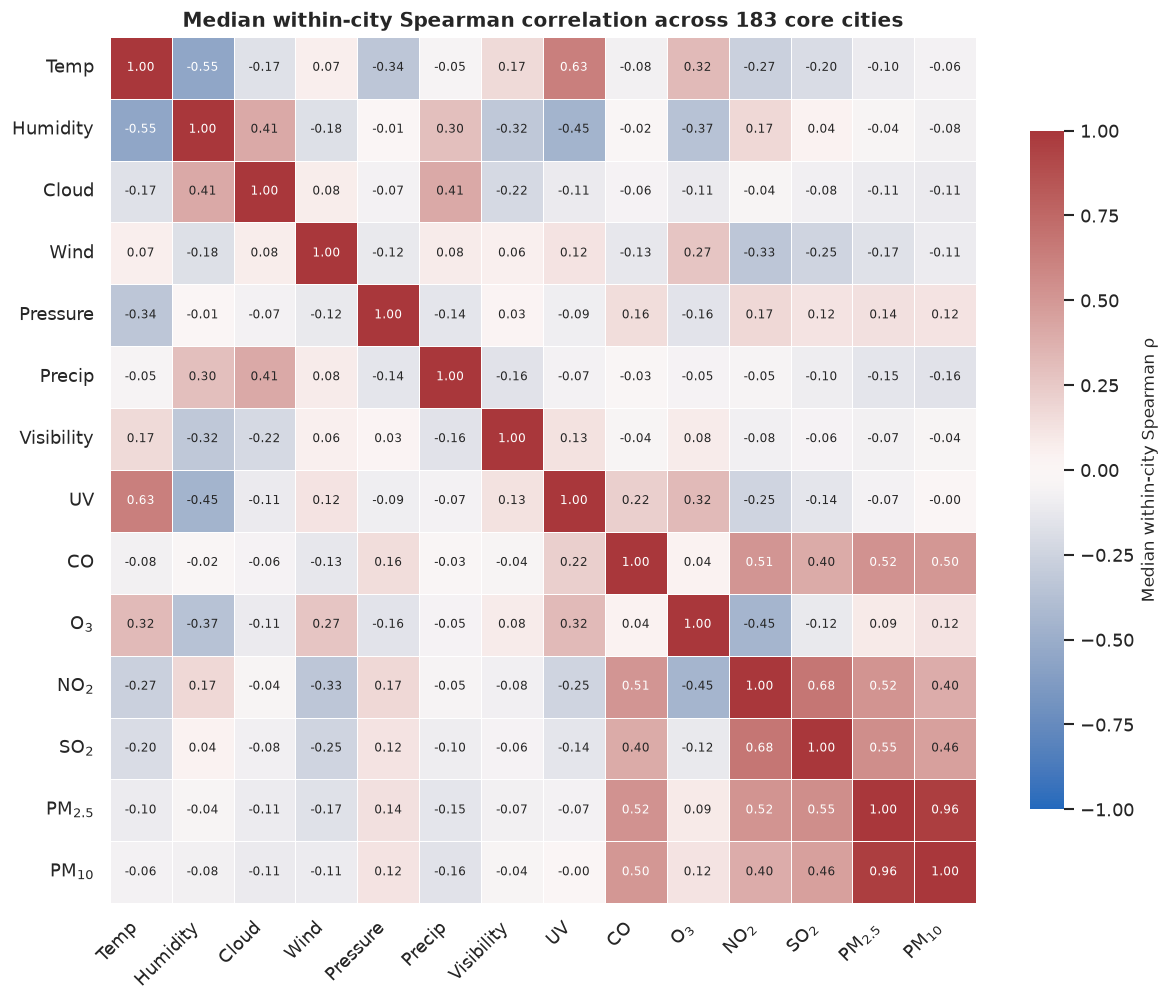

fig_08_within_city_correlations.png


,median_rho
humidity,-0.55
pressure_mb,-0.34
uv_index,0.63
air_quality_Ozone,0.32
air_quality_PM2.5,-0.10


In [9]:
corr = within_city_spearman(city_daily, CORRELATION_COLUMNS)
labels = [SHORT_LABELS[c] for c in CORRELATION_COLUMNS]

fig, ax = plt.subplots(figsize=(10.2, 8.4))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap=sns.color_palette("vlag", as_cmap=True),
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 7.2},
    cbar_kws={"shrink": 0.78, "label": "Median within-city Spearman ρ"},
    ax=ax,
)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels, rotation=0)
ax.set_title("Median within-city Spearman correlation across 183 core cities")
fig.tight_layout()
path = save_figure(fig, "fig_08_within_city_correlations.png")
plt.show()
print(path.name)
display(
    corr.loc[
        "temperature_celsius",
        ["humidity", "pressure_mb", "uv_index", "air_quality_Ozone", "air_quality_PM2.5"],
    ].round(2).to_frame("median_rho")
)

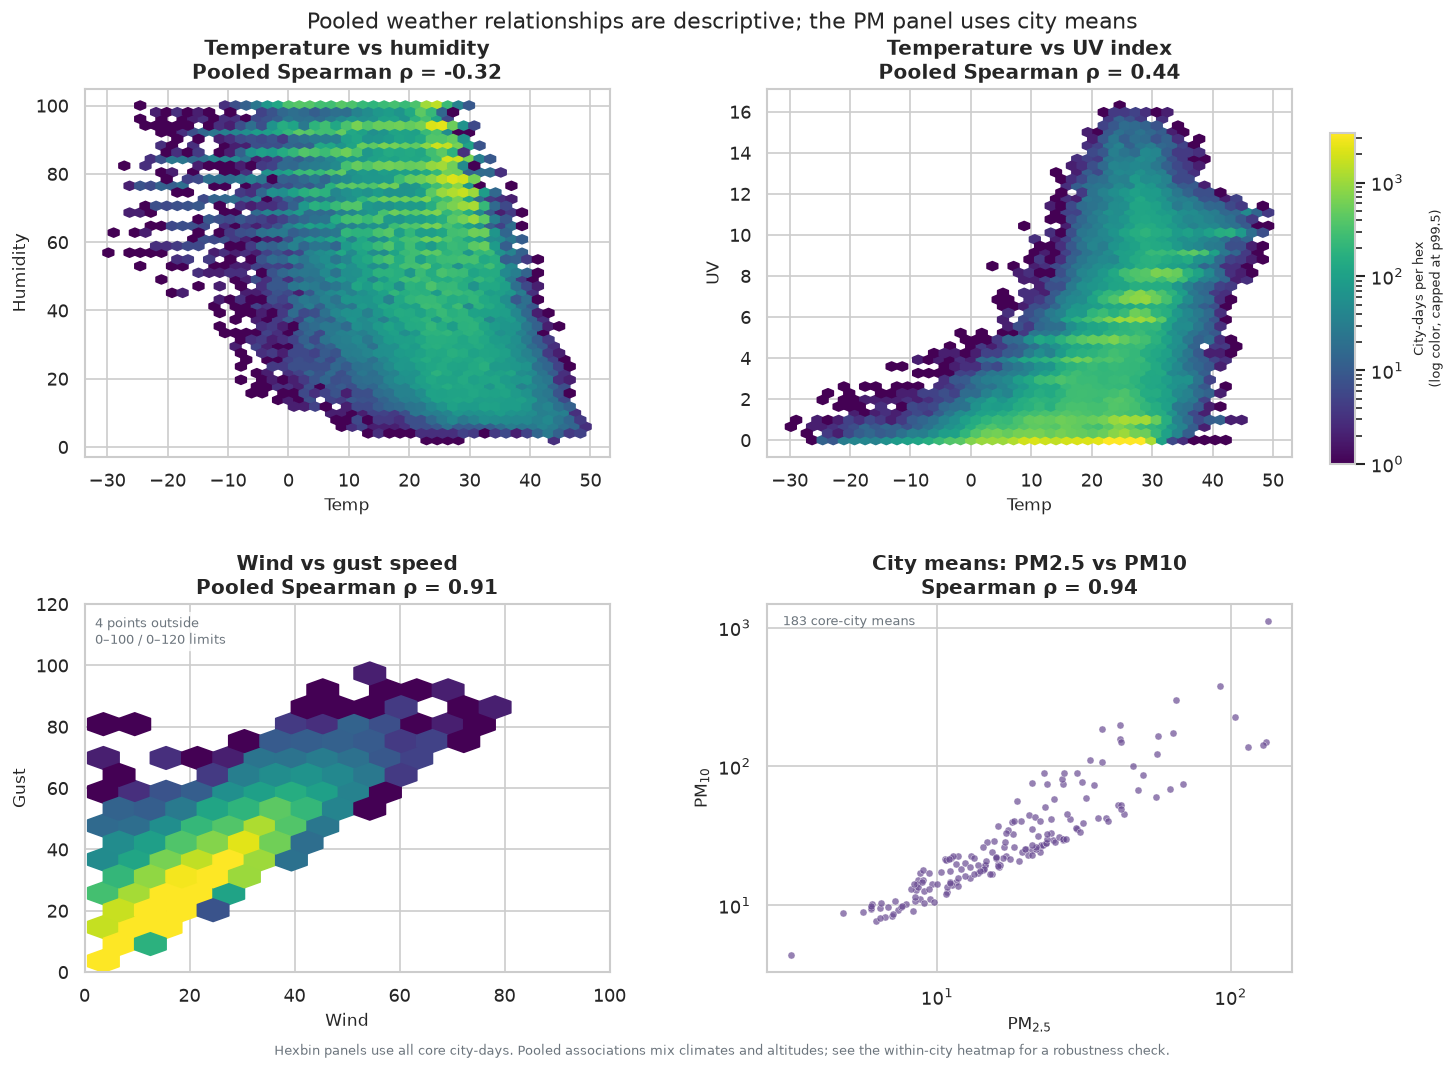

fig_09_weather_relationships.png


In [10]:
pairs = [
    ("temperature_celsius", "humidity", "Temperature vs humidity"),
    ("temperature_celsius", "uv_index", "Temperature vs UV index"),
    ("wind_kph", "gust_kph", "Wind vs gust speed"),
]

fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.2))
hexbins = []
for ax, (x_col, y_col, title) in zip([axes[0, 0], axes[0, 1], axes[1, 0]], pairs):
    sub = core[[x_col, y_col]].dropna()
    hb = ax.hexbin(
        sub[x_col],
        sub[y_col],
        gridsize=45,
        cmap="viridis",
        mincnt=1,
        norm=LogNorm(vmin=1),
    )
    hexbins.append(hb)
    rho = spearmanr(sub[x_col], sub[y_col]).statistic
    ax.set_xlabel(SHORT_LABELS.get(x_col, x_col))
    ax.set_ylabel(SHORT_LABELS.get(y_col, y_col))
    ax.set_title(f"{title}\nPooled Spearman ρ = {rho:.2f}")
    if x_col == "wind_kph":
        outside = int(((sub[x_col] > 100) | (sub[y_col] > 120)).sum())
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 120)
        ax.text(
            0.02,
            0.97,
            f"{outside} points outside\n0–100 / 0–120 limits",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=7.5,
            color="#6C757D",
            bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
        )

all_counts = np.concatenate([np.ma.filled(hb.get_array(), 0) for hb in hexbins])
color_cap = max(2.0, float(np.percentile(all_counts, 99.5)))
for hb in hexbins:
    hb.set_norm(LogNorm(vmin=1, vmax=color_cap))

ax = axes[1, 1]
pm_city = (
    core.groupby(["country", "city"])
    .agg(
        pm25=("air_quality_PM2.5", "mean"),
        pm10=("air_quality_PM10", "mean"),
    )
    .reset_index()
)
ax.scatter(
    pm_city["pm25"],
    pm_city["pm10"],
    s=18,
    alpha=0.7,
    color="#6A4C93",
    edgecolor="white",
    linewidth=0.3,
)
ax.set_xscale("log")
ax.set_yscale("log")
rho_city = spearmanr(pm_city["pm25"], pm_city["pm10"]).statistic
ax.set_xlabel(SHORT_LABELS["air_quality_PM2.5"])
ax.set_ylabel(SHORT_LABELS["air_quality_PM10"])
ax.set_title(f"City means: PM2.5 vs PM10\nSpearman ρ = {rho_city:.2f}")
ax.text(
    0.03,
    0.97,
    f"{len(pm_city)} core-city means",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=8,
    color="#6C757D",
)

fig.subplots_adjust(left=0.075, right=0.88, bottom=0.10, top=0.90, hspace=0.40, wspace=0.30)
cax = fig.add_axes([0.905, 0.56, 0.017, 0.30])
cbar = fig.colorbar(hexbins[0], cax=cax)
cbar.set_label("City-days per hex\n(log color, capped at p99.5)", fontsize=8)
fig.suptitle(
    "Pooled weather relationships are descriptive; the PM panel uses city means",
    fontsize=13,
    y=0.97,
)
fig.text(
    0.5,
    0.025,
    "Hexbin panels use all core city-days. Pooled associations mix climates and altitudes; see the within-city heatmap for a robustness check.",
    ha="center",
    fontsize=8,
    color="#6C757D",
)
path = save_figure(fig, "fig_09_weather_relationships.png")
plt.show()
print(path.name)


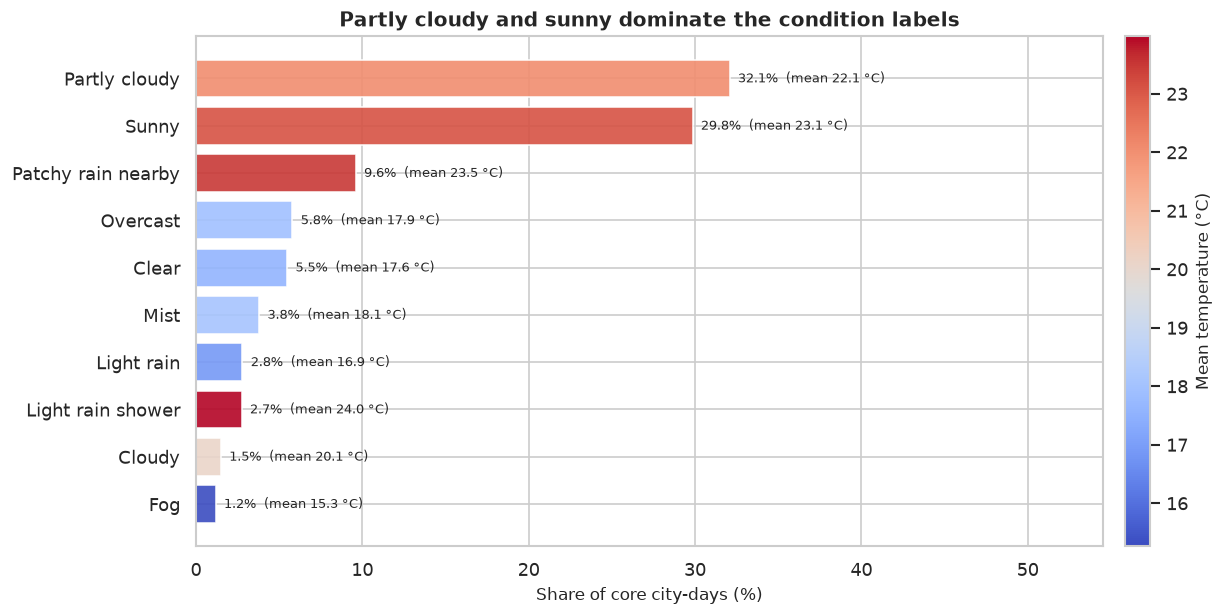

fig_10_condition_frequency.png


,n,share_pct,mean_temp
condition_text,,,
Partly cloudy,51286,32.1,22.067840
Sunny,47729,29.8,23.097007
Patchy rain nearby,15353,9.6,23.490207
Overcast,9268,5.8,17.934193
Clear,8761,5.5,17.577908
Mist,6070,3.8,18.060362
Light rain,4466,2.8,16.875280
Light rain shower,4387,2.7,23.979405
Cloudy,2395,1.5,20.095825


In [11]:
cond = (
    core.groupby("condition_text")
    .agg(
        n=("temperature_celsius", "size"),
        share=("temperature_celsius", lambda s: len(s) / len(core)),
        mean_temp=("temperature_celsius", "mean"),
    )
    .sort_values("n", ascending=False)
    .head(10)
    .sort_values("n", ascending=False)
)

fig, ax = plt.subplots(figsize=(11.0, 5.3))
y = np.arange(len(cond))
norm = Normalize(vmin=cond["mean_temp"].min(), vmax=cond["mean_temp"].max())
colors = plt.cm.coolwarm(norm(cond["mean_temp"].to_numpy()))
ax.barh(y, cond["share"] * 100, color=colors, alpha=0.9)
ax.set_yticks(y, [textwrap.fill(label, 28) for label in cond.index])
ax.invert_yaxis()
ax.set_xlabel("Share of core city-days (%)")
ax.set_title("Partly cloudy and sunny dominate the condition labels")
for ypos, row in enumerate(cond.itertuples()):
    ax.text(
        row.share * 100 + 0.5,
        ypos,
        f"{row.share * 100:.1f}%  (mean {row.mean_temp:.1f} °C)",
        va="center",
        fontsize=8,
    )
ax.set_xlim(0, cond["share"].max() * 100 * 1.7)
sm = ScalarMappable(norm=norm, cmap=plt.cm.coolwarm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("Mean temperature (°C)")
fig.tight_layout()
path = save_figure(fig, "fig_10_condition_frequency.png")
plt.show()
print(path.name)
display(cond.assign(share_pct=(cond["share"] * 100).round(1))[["n", "share_pct", "mean_temp"]])

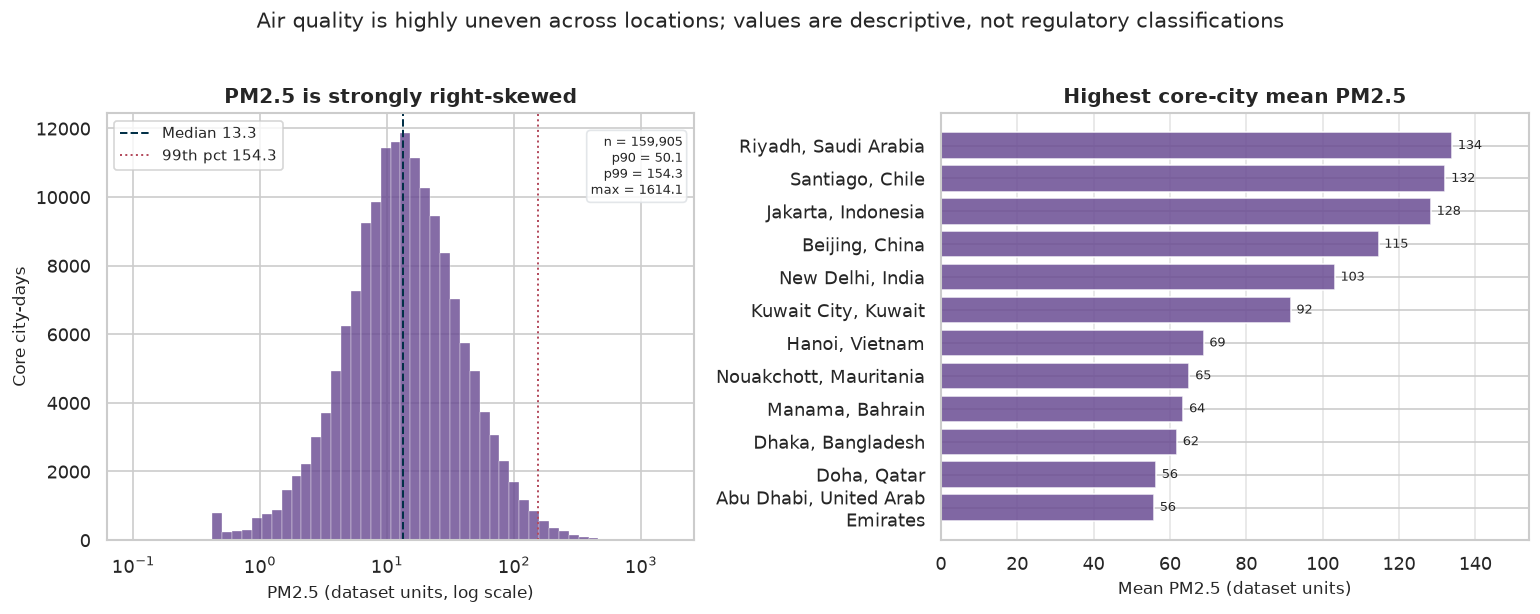

fig_11_pm25_air_quality.png


,country,city,pm25,n
137,Saudi Arabia,Riyadh,133.92,876
34,Chile,Santiago,132.16,874
71,Indonesia,Jakarta,128.36,877
35,China,Beijing,114.64,873
70,India,New Delhi,103.19,876
84,Kuwait,Kuwait City,91.64,876
179,Vietnam,Hanoi,68.82,876
100,Mauritania,Nouakchott,65.11,876
12,Bahrain,Manama,63.52,877
13,Bangladesh,Dhaka,61.86,876


In [12]:
pm = core["air_quality_PM2.5"].dropna()
pm_city = (
    core.groupby(["country", "city"])
    .agg(pm25=("air_quality_PM2.5", "mean"), n=("air_quality_PM2.5", "size"))
    .reset_index()
    .sort_values("pm25", ascending=False)
)
pm_top = pm_city.head(12).sort_values("pm25", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.0))

ax = axes[0]
ax.hist(
    pm,
    bins=np.logspace(np.log10(pm.min()), np.log10(pm.max()), 55),
    color="#6A4C93",
    alpha=0.82,
    edgecolor="white",
    linewidth=0.25,
)
ax.set_xscale("log")
ax.axvline(pm.median(), color="#023047", linestyle="--", linewidth=1.2, label=f"Median {pm.median():.1f}")
ax.axvline(pm.quantile(0.99), color="#B44C5E", linestyle=":", linewidth=1.2, label=f"99th pct {pm.quantile(0.99):.1f}")
ax.set_xlabel("PM2.5 (dataset units, log scale)")
ax.set_ylabel("Core city-days")
ax.set_title("PM2.5 is strongly right-skewed")
ax.legend(loc="upper left", frameon=True)
ax.text(
    0.98,
    0.95,
    f"n = {len(pm):,}\np90 = {pm.quantile(0.90):.1f}\np99 = {pm.quantile(0.99):.1f}\nmax = {pm.max():.1f}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "alpha": 0.85, "edgecolor": "#DEE2E6"},
)

ax = axes[1]
y = np.arange(len(pm_top))
ax.barh(y, pm_top["pm25"], color="#6A4C93", alpha=0.85)
ax.set_yticks(y, [textwrap.fill(f"{row.city}, {row.country}", 28) for row in pm_top.itertuples()])
ax.invert_yaxis()
ax.set_xlabel("Mean PM2.5 (dataset units)")
ax.set_title("Highest core-city mean PM2.5")
for ypos, value in enumerate(pm_top["pm25"]):
    ax.text(value + 1.5, ypos, f"{value:.0f}", va="center", fontsize=8)
ax.set_xlim(0, pm_top["pm25"].max() * 1.15)
ax.grid(axis="x", alpha=0.5)

fig.suptitle(
    "Air quality is highly uneven across locations; values are descriptive, not regulatory classifications",
    fontsize=12.5,
    y=1.02,
)
fig.tight_layout()
path = save_figure(fig, "fig_11_pm25_air_quality.png")
plt.show()
print(path.name)
display(pm_city.head(10).round(2))

## 6. EDA conclusions and caveats

The final cell writes `reports/eda_summary.md` with the actual values
computed in this executed notebook. No model results are included.

In [13]:
usable = global_daily.loc[global_daily["coverage_ok"]].copy()
monthly = monthly_global(global_daily)
amp = seasonal_amplitude(city_daily)
cs = city_temperature_summary(city_daily)
corr = within_city_spearman(city_daily, CORRELATION_COLUMNS)
pm_city = (
    core.groupby(["country", "city"])
    .agg(pm25=("air_quality_PM2.5", "mean"), n=("air_quality_PM2.5", "size"))
    .reset_index()
)
cond = (
    core.groupby("condition_text")
    .agg(n=("temperature_celsius", "size"), mean_temp=("temperature_celsius", "mean"))
    .sort_values("n", ascending=False)
)

hot = cs.nlargest(1, "mean_temp").iloc[0]
cold = cs.nsmallest(1, "mean_temp").iloc[0]
amp_top = amp.nlargest(1, "amplitude").iloc[0]
amp_bottom = amp.nsmallest(1, "amplitude").iloc[0]
pm_top = pm_city.nlargest(1, "pm25").iloc[0]
pm_bottom = pm_city.nsmallest(1, "pm25").iloc[0]
month_min = monthly.loc[monthly["mean_temp"].idxmin()]
month_max = monthly.loc[monthly["mean_temp"].idxmax()]
lat_rho = spearmanr(amp["lat"], amp["mean_temp"]).statistic
sunny_share = 100 * core["condition_text"].isin(["Sunny", "Partly cloudy"]).mean()
rain_share = 100 * core["condition_text"].str.contains(
    "rain|drizzle|thunder", case=False, regex=True
).mean()
pm = core["air_quality_PM2.5"].dropna()

lines = f'''# Phase C EDA summary

Generated from the executed `notebooks/02_eda.ipynb`.

## Scope

Descriptive analysis of the cleaned Global Weather Repository data. The global
headline series uses the 183 core locations, equal-weighted by city, and only
the 875 of 879 UTC dates with `coverage_ok == True`. No forecasting model was
trained and no forecast metric was calculated.

## Key findings

- **Coverage:** {len(cs)} core cities; {len(core):,} core city-days. The global
  core series has {int(global_daily["coverage_ok"].sum())} usable UTC dates out
  of {len(global_daily)}.
- **Global level:** the usable global daily mean is
  **{usable["temperature_celsius"].mean():.2f} °C**, with daily values from
  {usable["temperature_celsius"].min():.2f} to
  {usable["temperature_celsius"].max():.2f} °C. The minimum occurs on
  {usable.loc[usable["temperature_celsius"].idxmin(), "date_utc"]:%d %b %Y} and
  the maximum on
  {usable.loc[usable["temperature_celsius"].idxmax(), "date_utc"]:%d %b %Y}.
- **Seasonality:** monthly means range from
  **{month_min["mean_temp"]:.2f} °C** in {month_min["month_label"]} to
  **{month_max["mean_temp"]:.2f} °C** in {month_max["month_label"]}, an
  amplitude of {monthly["mean_temp"].max() - monthly["mean_temp"].min():.2f} °C.
  This is a 2.5-year descriptive pattern, not a climate trend.
- **City differences:** {hot["city"]} has the highest core-city mean
  ({hot["mean_temp"]:.2f} °C); {cold["city"]} has the lowest
  ({cold["mean_temp"]:.2f} °C), a city-mean range of
  {cs["mean_temp"].max() - cs["mean_temp"].min():.2f} °C.
- **Seasonal amplitude:** {amp_top["city"]} has the largest monthly amplitude
  ({amp_top["amplitude"]:.1f} °C); {amp_bottom["city"]} has the smallest
  ({amp_bottom["amplitude"]:.1f} °C). This contrast is consistent with
  continental versus tropical maritime climates.
- **Latitude:** the Spearman correlation between latitude and city mean
  temperature is **{lat_rho:.2f}**, so latitude is informative but not
  sufficient; altitude and local climate matter (for example, Quito at the
  equator is much cooler than Singapore).
- **Within-city associations with temperature:** median Spearman ρ is
  {corr.loc["temperature_celsius", "humidity"]:.2f} for humidity,
  {corr.loc["temperature_celsius", "uv_index"]:.2f} for UV,
  {corr.loc["temperature_celsius", "pressure_mb"]:.2f} for pressure,
  {corr.loc["temperature_celsius", "air_quality_Ozone"]:.2f} for ozone, and
  {corr.loc["temperature_celsius", "air_quality_PM2.5"]:.2f} for PM2.5.
  These are descriptive associations, not causal effects.
- **Conditions:** {sunny_share:.1f}% of core city-days are labelled Sunny or
  Partly cloudy; rain/drizzle/thunder labels account for {rain_share:.1f}%.
  Rare dust/sandstorm labels are associated with much warmer conditions, but the labels
  are not independent physical measurements.
- **Air quality:** PM2.5 has median {pm.median():.1f}, 90th percentile
  {pm.quantile(0.90):.1f}, and 99th percentile {pm.quantile(0.99):.1f}
  (dataset units). {pm_top["city"]} has the highest core-city mean
  ({pm_top["pm25"]:.1f}); {pm_bottom["city"]} has the lowest
  ({pm_bottom["pm25"]:.1f}). Units are not documented in the Kaggle schema, so
  absolute regulatory comparisons are avoided.

## Figures

| Figure | What it shows |
|---|---|
| `fig_01_coverage_summary.png` | City-day rows and groups by tier; global core coverage distribution |
| `fig_02_global_temperature_and_coverage.png` | Global daily core temperature, 30-day rolling mean, and city coverage |
| `fig_03_monthly_seasonal_cycle.png` | Monthly global series and calendar-month seasonal cycle |
| `fig_04_temperature_distributions.png` | Core city-day and city-mean temperature distributions |
| `fig_05_city_temperature_extremes.png` | Hottest and coolest core cities with observed ranges |
| `fig_06_seasonal_amplitude.png` | Largest and smallest city seasonal amplitudes |
| `fig_07_latitude_and_temperature.png` | City mean temperature versus latitude, colored by amplitude |
| `fig_08_within_city_correlations.png` | Median within-city Spearman correlations |
| `fig_09_weather_relationships.png` | Pooled hexbin relationships plus a city-mean PM2.5/PM10 panel |
| `fig_10_condition_frequency.png` | Most frequent condition labels and their mean temperatures |
| `fig_11_pm25_air_quality.png` | PM2.5 distribution and highest city means |

## Caveats for modelling

- The global series is an **equal-weighted panel average**, not a population-
  or area-weighted global temperature.
- The record is only May 2024–October 2026; annual comparisons are incomplete
  because 2024 starts in May and 2026 ends in October.
- Only 183 of 269 country+city groups have near-complete coverage. Sparse
  groups must not be used for city-level forecasting.
- Four global UTC dates have severe coverage dips and are excluded from the
  headline series via `coverage_ok`.
- City labels and country labels are only partially normalised; unusual place
  names were retained when coordinates were consistent with the stated country.
- Air-quality units are not documented in the source schema.
- These EDA associations do not establish causality and do not select a
  forecasting model.
'''

summary_path = REPORT_DIR / "eda_summary.md"
summary_path.write_text(lines, encoding="utf-8")
print(f"Wrote {summary_path}")
print(lines[:1200])


Wrote D:\PMA\pma-data-analytics\reports\eda_summary.md
# Phase C EDA summary

Generated from the executed `notebooks/02_eda.ipynb`.

## Scope

Descriptive analysis of the cleaned Global Weather Repository data. The global
headline series uses the 183 core locations, equal-weighted by city, and only
the 875 of 879 UTC dates with `coverage_ok == True`. No forecasting model was
trained and no forecast metric was calculated.

## Key findings

- **Coverage:** 183 core cities; 159,905 core city-days. The global
  core series has 875 usable UTC dates out
  of 879.
- **Global level:** the usable global daily mean is
  **21.48 °C**, with daily values from
  13.51 to
  27.80 °C. The minimum occurs on
  21 Jan 2026 and
  the maximum on
  19 Jul 2024.
- **Seasonality:** monthly means range from
  **14.56 °C** in 2026-01 to
  **27.02 °C** in 2024-07, an
  amplitude of 12.45 °C.
  This is a 2.5-year descriptive pattern, not a climate trend.
- **City differences:** Doha has the highest core-city mean

## Phase C checkpoint

Phase C is complete for review:

- EDA figures are saved in `reports/figures/`.
- `reports/eda_summary.md` records the actual computed values and the
  modelling caveats.
- No model has been trained; no MAE, RMSE, MAPE, or sMAPE exists yet.
- The next phase is forecasting: a chronological split, naive baseline,
  and stronger models with leakage controls.

Stop here for review before Phase D.